# 01 Preprocessing - Zhang 2019 Follicular Lymphoma (malignant compartment)

Isolate malignant B cells, integrate the four tumour samples across two patients
(Harmony on `sample`), embed, and read **Gate 1** (batch-mixing + manifold continuity)
directly on the regenerated embedding across an integration-strength (theta) sweep.

Follicular-lymphoma malignant cells are patient-specific clones (unique BCR / CNV), so
pre-integration each cell's neighbours are almost entirely same-sample; the theta sweep
is what resolves whether one continuous, sample-mixed manifold exists.

In [1]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/mesencontext/claude/<Category>/<Dataset>
name = os.path.basename(os.getcwd())                    # dataset (folder minus 'Data_')
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Category partition
pth  = os.path.join(*([os.pardir]*4))                   # -> EMToolbox root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'mesencontext'))
from scripts.load import load_CCCA_adata

# '-1' re-run notebooks read the same raw input as the base dataset (strip the -N suffix)
name_data = name.split('-')[0]
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', 'Data_' + name_data)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat)

dataset: Zhang2019_Hematologic-1 | category: Hematologic


### Load malignant compartment
Zhang et al. annotate cell type directly; we take their `Malignant` calls (malignant B cells).

In [3]:
adata = load_CCCA_adata(pth_in)
print('full atlas:', adata.shape)
adata = adata[adata.obs.celltype == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique())
print('expression: X max %.2f (log1p of normalize_total UMI counts)' % adata.X.max())

Loading ../../../../../../data/unzip/CCCA/Data_Zhang2019_Hematologic
Done.
full atlas: (7002, 24410)
malignant: (5645, 24410) | samples: 4
expression: X max 7.33 (log1p of normalize_total UMI counts)


### Sample thresholding - all four samples retained
Per-sample malignant counts are 680 / 684 / 1876 / 2405. The smallest (680) is an order
of magnitude above any under-population floor (Puram used >=100). A multiplicative
gap-finder would read the ~2x cliff between the two large and two small samples as a
threshold and delete both **primary-FL** samples, but that gap is the natural 2-large /
2-small split of a four-sample set, not a thin-sample cliff (the gap-finding premise is
not met). We keep all four samples; batch structure is handled by integration, not by
discarding half the biology.

In [4]:
n = adata.obs['sample'].value_counts()
print('per-sample malignant counts:', n.to_dict())
print('minimum sample size %d >> under-population floor (100) -> keep all %d samples' % (n.min(), len(n)))
print('progression status per sample:',
      adata.obs.groupby('sample', observed=True)['progression_status'].first().to_dict())

per-sample malignant counts: {'FL1018T2': 2405, 'FL2001T2': 1876, 'FL2001T1': 684, 'FL1018T1': 680}
minimum sample size 680 >> under-population floor (100) -> keep all 4 samples
progression status per sample: {'FL1018T1': 'primary', 'FL1018T2': 'transformed (DLBCL)', 'FL2001T1': 'primary', 'FL2001T2': 'progressed'}


### Overdispersion, PCA, Harmony integration-strength (theta) sweep
`theta` sets integration strength. We sweep it and summarise mixing with **iLISI**
(inverse-Simpson effective number of samples among each cell's 30 neighbours; max = 4).
The read that decides Gate 1 is the embedding itself (below), not this scalar.

In [5]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=30):
    nn = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; ncat = codes.max()+1
    return np.array([1.0/np.sum((np.bincount(codes[nn[i]], minlength=ncat)/k)**2)
                     for i in range(len(codes))])
s = adata.obs['sample'].values
print('pre-Harmony iLISI (20 PC): mean %.2f (1 = unmixed, 4 = fully mixed)'
      % ilisi(adata.obsm['X_pca'][:,:20], s).mean())
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    print('theta=%2d -> iLISI (15 PC) mean %.2f' % (th, ilisi(adata.obsm['X_pca_harmony'][:,:15], s).mean()))
theta, n_pcs = 10, 15
print('selected theta=%d, n_pcs=%d (mixing rises monotonically; manifold stays one mass)' % (theta, n_pcs))

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 636 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 636
pre-Harmony iLISI (20 PC): mean 1.04 (1 = unmixed, 4 = fully mixed)
theta= 2 -> iLISI (15 PC) mean 1.42
theta= 5 -> iLISI (15 PC) mean 1.98
theta=10 -> iLISI (15 PC) mean 2.26
selected theta=10, n_pcs=15 (mixing rises monotonically; manifold stays one mass)


In [6]:
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=30, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

### Remove detached islands (data-driven)
Radius graph on the UMAP (6x the median nearest-neighbour distance); keep the largest
connected component. Strips physically detached specks without touching the main mass.

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print('detached-island cells removed:', int((lab!=main).sum()), 'in', ncomp-1, 'islands')
adata = adata[lab==main].copy()
print('cells retained:', adata.shape[0])

detached-island cells removed: 0 in 0 islands
cells retained: 5645


### Sub-region biology before the gate (proliferation check)
Before certifying Gate 1 we confirm the only sub-structure - a small cycling tip - is
not a developmentally-distinct lobe demanding scoping. Low-resolution Leiden splits two
lobes; we compare cycling fraction and (provisional) developmental scores per lobe.

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', flavor='igraph',
             n_iterations=2, directed=False, random_state=SEED)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['G1/S','G2/M','Intermediate'])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
g_ref = feat['union'].loc[feat['union'].isin(adata.var_names)]
for src,l in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    sc.tl.score_genes(adata, gene_list=g, score_name=l, ctrl_as_ref=False, gene_pool=g_ref, random_state=1234)
tab = adata.obs.groupby('lobe', observed=True).agg(
    n=('cycling','size'), cycling_frac=('cycling','mean'),
    Gast=('Gast','mean'), pSom=('pSom','mean'), Crest=('Crest','mean'))
print(tab.round(3).to_string())
print('-> developmental scores near-identical across lobes; proliferation split is orthogonal to the developmental axis -> keep whole manifold (no scoping).')
for c in ['lobe','cycling','Gast','pSom','Crest']: del adata.obs[c]

         n  cycling_frac   Gast   pSom  Crest
lobe                                         
0     4182         0.079  0.011  0.005  0.010
1     1463         0.316  0.013  0.011  0.008
-> developmental scores near-identical across lobes; proliferation split is orthogonal to the developmental axis -> keep whole manifold (no scoping).


### Gate 1 - batch mixing & manifold continuity (theta sweep on the embedding)
The three-row sweep is the Gate-1 evidence. At **theta=2** the manifold is a per-patient
archipelago (two blobs split by patient); at **theta=10** all four samples and both
patients intermix across one continuous connected mass.

Gate 1: theta=2 splits by patient (archipelago); theta=10 intermixes all 4 samples on one continuous mass.
kNN-graph connected components at theta=10: 1
Gate 1: mixed AND continuous -> GO


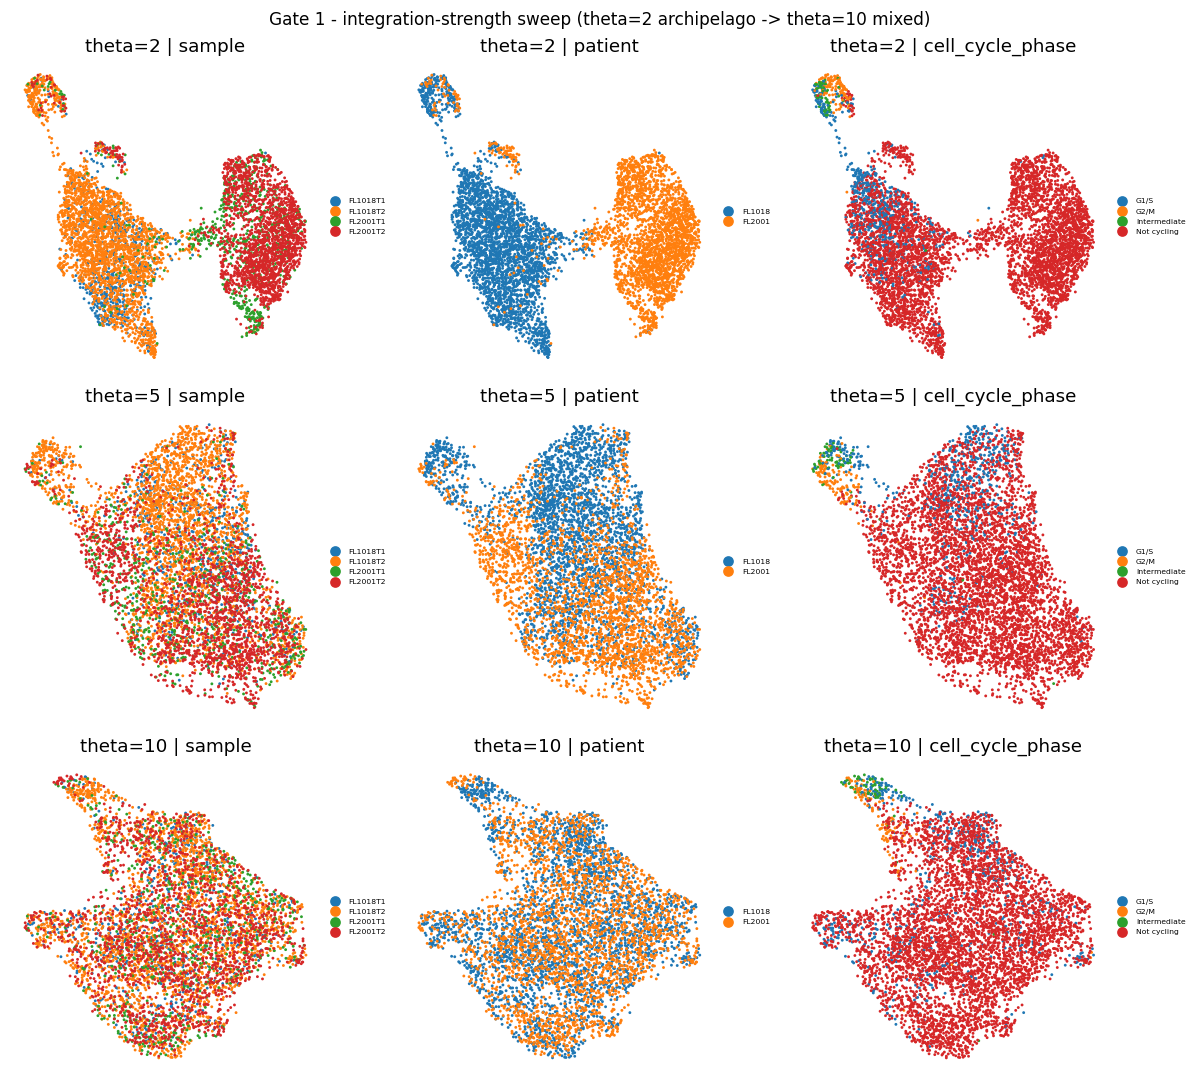

In [9]:
plot = adata.copy(); plot.obs['patient'] = plot.obs['patient'].astype('category')
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for ri, th in enumerate([2, 5, 10]):
    sce.pp.harmony_integrate(plot, 'sample', theta=th, max_iter_harmony=30, random_state=SEED)
    sc.pp.neighbors(plot, n_pcs=n_pcs, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
    sc.tl.umap(plot, spread=1.3, random_state=SEED)
    for ci, col in enumerate(['sample','patient','cell_cycle_phase']):
        ax = axes[ri, ci]
        sc.pl.umap(plot, color=col, size=14, frameon=False, show=False, ax=ax,
                   legend_fontsize=5, title='theta=%d | %s' % (th, col))
fig.suptitle('Gate 1 - integration-strength sweep (theta=2 archipelago -> theta=10 mixed)', size=11)
fig.tight_layout()
print('Gate 1: theta=2 splits by patient (archipelago); theta=10 intermixes all 4 samples on one continuous mass.')
print('kNN-graph connected components at theta=10:', connected_components(adata.obsp['connectivities'], directed=False)[0])
print('Gate 1: mixed AND continuous -> GO')

### Save processed data

In [10]:
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (5645, 14715)


### Sample-integration figure (deliverable)

saved samples.pdf | cells: 5645


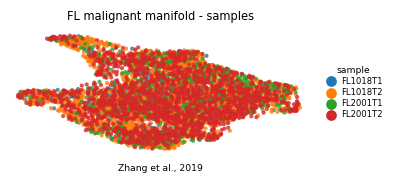

In [11]:
# House style: figsize=(3.5,1.5) horizontal strip, size=30, colour=sample.
# Intermixing of all four samples across one continuous manifold is the Gate-1 evidence.
plot = adata.copy()
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('FL malignant manifold - samples', size=7.5)
ax.text(.5,-.12,'Zhang et al., 2019', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])